In [19]:
import math, os, time
from collections import defaultdict
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt

In [20]:
SUPPORT      = 0.001   # minimum support
MIN_CONF     = 0.05    # minimum confidence of a rule
MIN_LIFT     = 1.0     # minimum lift (1.0 = discards uninteresting rules)
TOP_K        = 10      # how many songs to recommend
EVAL_USERS   = 5000    # test users for evaluation
SEED         = 0

DATA = next(p / "data" for p in (Path.cwd(), *Path.cwd().parents) if (p / "data").is_dir())
NPZ    = DATA / "lyrics_100_10.npz"
TRACKS = DATA / "unique_tracks.txt"

In [21]:
d = np.load(NPZ)
song_ids = d["song_id"]

_, user_idx = np.unique(d["user"], return_inverse=True)
n_songs = len(song_ids)
X = sp.csr_matrix((np.ones(len(user_idx), dtype=np.int8), (user_idx, d["song"])),
                  shape=(user_idx.max() + 1, n_songs))
X.sum_duplicates()

print(f"users (baskets): {X.shape[0]:,} | songs (items): {X.shape[1]:,} | interactions: {X.nnz:,}")

wanted, label = set(song_ids.tolist()), {}
with open(TRACKS, encoding="utf-8", errors="replace") as f:
    for line in f:
        _, sid, artist, title = line.rstrip("\r\n").split("<SEP>", 3)
        if sid in wanted and sid not in label:
            label[sid] = f"{artist} - {title}"
song_name = np.array([label.get(s, s) for s in song_ids], dtype=object)

users (baskets): 955,630 | songs (items): 35,690 | interactions: 23,347,259


In [22]:
def iter_baskets(X):
    ind, ptr = X.indices, X.indptr
    for u in range(X.shape[0]):
        yield ind[ptr[u]:ptr[u + 1]]

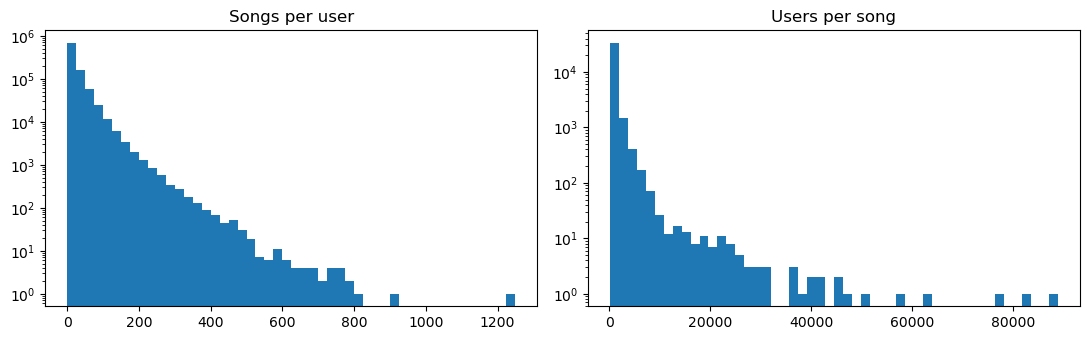

songs per user: median 14, max 1249
users per song:  median 279, max 88813


In [23]:
basket_sizes = np.diff(X.indptr)
item_counts_all = np.bincount(X.indices, minlength=X.shape[1])

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(basket_sizes, bins=50); ax[0].set_title("Songs per user"); ax[0].set_yscale("log")
ax[1].hist(item_counts_all[item_counts_all > 0], bins=50); ax[1].set_title("Users per song"); ax[1].set_yscale("log")
plt.tight_layout(); plt.show()

print(f"songs per user: median {np.median(basket_sizes):.0f}, max {basket_sizes.max()}")
print(f"users per song:  median {np.median(item_counts_all[item_counts_all > 0]):.0f}, max {item_counts_all.max()}")

In [24]:
def pass1_items(X, s_count):
    counts = np.bincount(X.indices, minlength=X.shape[1])
    freq = np.flatnonzero(counts >= s_count)
    table = np.zeros(X.shape[1], dtype=np.int32)                    # 0 = not frequent
    table[freq] = np.arange(1, len(freq) + 1, dtype=np.int32)
    return counts, freq, table

n_baskets = X.shape[0]
s_count = math.ceil(SUPPORT * n_baskets)
counts, freq, table = pass1_items(X, s_count)
m = len(freq)

print(f"support {SUPPORT} sobre {n_baskets:,} usuarios -> mínimo {s_count} usuarios")
print(f"songs frequent: {m:,} of {X.shape[1]:,}")
print(f"possible pairs between them: {m * (m - 1) // 2:,}  (upper triangular matrix of {m * (m - 1) // 2 * 4 / 1e6:,.0f} MB)")

support 0.001 sobre 955,630 usuarios -> mínimo 956 usuarios
songs frequent: 5,173 of 35,690
possible pairs between them: 13,377,378  (upper triangular matrix of 54 MB)


In [25]:
def pass2_pairs(X, table, m, s_count, method="triangular", max_gb=1.0):
    size = m * (m - 1) // 2
    use_tri = method == "triangular" and size * 4 / 1e9 <= max_gb
    print("method:", "upper triangular matrix" if use_tri else "triples")
    if use_tri:
        counts = np.zeros(size, dtype=np.int32)
    else:
        triples, buf, buf_n = {}, [], 0

    def flush():
        nonlocal buf, buf_n
        if buf:
            keys, c = np.unique(np.concatenate(buf), return_counts=True)
            for key, cnt in zip(keys.tolist(), c.tolist()):
                triples[key] = triples.get(key, 0) + cnt
        buf, buf_n = [], 0

    tri_cache = {}
    for items in iter_baskets(X):
        b = table[items]
        b = np.sort(b[b > 0]) - 1
        L = len(b)
        if L < 2:
            continue
        if L not in tri_cache:
            tri_cache[L] = np.triu_indices(L, 1)
            if L > 200:
                tri_cache.pop(L)
        I, J = tri_cache.get(L) or np.triu_indices(L, 1)
        ii, jj = b[I].astype(np.int64), b[J].astype(np.int64)
        if use_tri:
            counts[ii * m - ii * (ii + 1) // 2 + (jj - ii - 1)] += 1
        else:
            buf.append(ii * m + jj); buf_n += len(ii)
            if buf_n > 5_000_000:
                flush()

    if use_tri:
        ks = np.flatnonzero(counts >= s_count)
        rows = np.arange(m, dtype=np.int64)
        starts = rows * m - rows * (rows + 1) // 2
        i = np.searchsorted(starts, ks, side="right") - 1
        j = ks - starts[i] + i + 1
        return i, j, counts[ks]
    flush()
    keys = np.array([k for k, v in triples.items() if v >= s_count], dtype=np.int64)
    c = np.array([triples[k] for k in keys.tolist()], dtype=np.int64)
    return keys // m, keys % m, c

t0 = time.time()
pi, pj, pc = pass2_pairs(X, table, m, s_count)
print(f"frequent pairs: {len(pc):,}  ({time.time() - t0:.1f} s)")

method: upper triangular matrix
frequent pairs: 12,393  (34.7 s)


In [26]:
# top 10 most frequent pairs
top = np.argsort(-pc)[:10]
s1, s2 = freq[pi[top]], freq[pj[top]]
pd.DataFrame({"song_1": s1, "song_2": s2, "name_1": song_name[s1], "name_2": song_name[s2],
              "users with both": pc[top], "support": pc[top] / n_baskets})

,song_1,song_2,name_1,name_2,users with both,support
0,99,100,Björk - Undo,Dwight Yoakam - You're The One,50670,0.053023
1,103,108,Train - Hey_ Soul Sister,OneRepublic - Secrets,28722,0.030056
2,108,111,OneRepublic - Secrets,Train - Marry Me,25715,0.026909
3,99,882,Björk - Undo,Cartola - Tive Sim,24372,0.025504
4,99,108,Björk - Undo,OneRepublic - Secrets,24118,0.025238
5,103,111,Train - Hey_ Soul Sister,Train - Marry Me,23682,0.024782
6,100,108,Dwight Yoakam - You're The One,OneRepublic - Secrets,23598,0.024694
7,100,882,Dwight Yoakam - You're The One,Cartola - Tive Sim,22645,0.023696
8,100,113,Dwight Yoakam - You're The One,Sam Cooke - Ain't Misbehavin,22368,0.023407
9,99,113,Björk - Undo,Sam Cooke - Ain't Misbehavin,22140,0.023168


In [27]:
itemsets = {(int(s),): int(counts[s]) for s in freq}
level = {(a, b): c for a, b, c in zip(pi.tolist(), pj.tolist(), pc.tolist())}
for t, c in level.items():
    itemsets[(int(freq[t[0]]), int(freq[t[1]]))] = c
    
pd.Series(pd.Series([len(t) for t in itemsets]).value_counts().sort_index(), name="itemsets frecuentes")

1     5173
2    12393
Name: itemsets frecuentes, dtype: int64

In [28]:
def make_rules(itemsets, n, min_conf, min_lift):
    rows = []
    for iset, c in itemsets.items():
        if len(iset) < 2:
            continue
        for j in iset:
            ant = tuple(x for x in iset if x != j)
            conf = c / itemsets[ant]
            sup_j = itemsets[(j,)] / n
            lift = conf / sup_j
            if conf >= min_conf and lift >= min_lift:
                rows.append((ant, j, c / n, conf, lift, conf - sup_j))
    return pd.DataFrame(rows, columns=["antecedent", "consequent", "support", "confidence", "lift", "interest"])

rules = make_rules(itemsets, n_baskets, MIN_CONF, MIN_LIFT)
print(f"{len(rules):,} rules with confidence ≥ {MIN_CONF} and lift ≥ {MIN_LIFT}")
top_rules = rules.sort_values("lift", ascending=False).head(10).copy()
top_rules["antecedent_name"] = top_rules["antecedent"].map(lambda a: " + ".join(song_name[list(a)]))
top_rules["consequent_name"] = song_name[top_rules["consequent"].to_numpy()]
top_rules

22,685 rules with confidence ≥ 0.05 and lift ≥ 1.0


,antecedent,consequent,support,confidence,lift,interest,antecedent_name,consequent_name
21556,"(4190,)",4191,0.001036,0.801619,607.013929,0.800299,The Avett Brothers - Incomplete And Insecure,The Avett Brothers - It Goes On And On
21555,"(4191,)",4190,0.001036,0.784469,607.013929,0.783177,The Avett Brothers - It Goes On And On,The Avett Brothers - Incomplete And Insecure
21983,"(18200,)",5444,0.001026,0.770440,542.161869,0.769019,Angus & Julia Stone - Another Day,Angus & Julia Stone - A Book Like This
21984,"(5444,)",18200,0.001026,0.721649,542.161869,0.720318,Angus & Julia Stone - A Book Like This,Angus & Julia Stone - Another Day
22061,"(6582,)",5912,0.001231,0.846043,538.643724,0.844472,José González - The Nest,José González - Fold
22062,"(5912,)",6582,0.001231,0.783478,538.643724,0.782023,José González - Fold,José González - The Nest
19502,"(1672,)",18242,0.001015,0.681658,527.460147,0.680366,Beach House - Take Care,Beach House - Real Love
19501,"(18242,)",1672,0.001015,0.785425,527.460147,0.783936,Beach House - Real Love,Beach House - Take Care
21567,"(4204,)",4191,0.001051,0.669333,506.842324,0.668013,The Avett Brothers - Slight Figure Of Speech,The Avett Brothers - It Goes On And On
21568,"(4191,)",4204,0.001051,0.795563,506.842324,0.793993,The Avett Brothers - It Goes On And On,The Avett Brothers - Slight Figure Of Speech


In [29]:
ant_songs = np.unique([a[0] for a in rules["antecedent"] if len(a) == 1])
has_rule = np.zeros(X.shape[1], dtype=np.int32)
has_rule[ant_songs] = 1
covered = (X @ has_rule) > 0        # dothey have at least one song that is an antecedent of a rule?

print(f"users with at least one applicable rule: {covered.mean():.1%}  ({covered.sum():,} of {X.shape[0]:,})")

users with at least one applicable rule: 89.6%  (856,571 of 955,630)


In [30]:
# recommending
class Recommender:
    def __init__(self, rules, n_songs):
        self.n_songs = n_songs
        size = rules["antecedent"].map(len).to_numpy()
        s = rules[size == 1]                                          # rules with 1 song in antecedent
        a0 = np.array([a[0] for a in s["antecedent"]], dtype=np.int64)
        cons = s["consequent"].to_numpy(np.int64)
        conf = s["confidence"].to_numpy(np.float32)
        order = np.argsort(a0, kind="stable")
        a0, cons, conf = a0[order], cons[order], conf[order]
        keys, start = np.unique(a0, return_index=True)
        end = np.append(start[1:], len(a0))
        self.single = {int(k): (cons[a:b], conf[a:b]) for k, a, b in zip(keys, start, end)}
        mu = rules[size > 1]                                          # rules with 2+ songs
        self.m_ant, self.m_cons, self.m_conf = mu["antecedent"].tolist(), mu["consequent"].tolist(), mu["confidence"].tolist()
        self.by_item = defaultdict(list)
        for r, ant in enumerate(self.m_ant):
            for x in ant:
                self.by_item[x].append(r)

    def recommend(self, basket, k=10):
        S = set(np.asarray(basket).tolist())
        scores = np.zeros(self.n_songs, dtype=np.float32)
        for x in S:
            if x in self.single:
                c, w = self.single[x]
                scores[c] += w
        seen = set()
        for x in S:
            for r in self.by_item.get(x, ()):
                if r not in seen:
                    seen.add(r)
                    if all(a in S for a in self.m_ant[r]):
                        scores[self.m_cons[r]] += self.m_conf[r]
        if S:
            scores[list(S)] = 0                                       # not recommending what they already have
        k = min(k, self.n_songs - 1)
        top = np.argpartition(-scores, k)[:k]
        top = top[np.argsort(-scores[top])]
        return [(int(t), float(scores[t])) for t in top if scores[t] > 0]

rec = Recommender(rules, X.shape[1])

In [31]:
u = int(np.argmax(basket_sizes >= 20))
basket = X.indices[X.indptr[u]:X.indptr[u + 1]]
print(f"user {u} has {len(basket)} songs, for example:")
for s in basket[:5]:
    print(f"  {s:>7}   {song_name[s]}")
print("\nrecommendations (song, score, name):")
for song, score in rec.recommend(basket, TOP_K):
    print(f"  {song:>7}   {score:.3f}   {song_name[song]}")

user 0 has 53 songs, for example:
        0   Billy Preston - Nothing from Nothing
        1   Josh Rouse - Under Cold Blue Stars
        2   Eric Hutchinson - Food Chain (Album Version)
        3   Jack Johnson - Constellations
        4   Zero 7 - You're My Flame [Album Version]

recommendations (song, score, name):
     2294   1.960   Fleet Foxes - Sun It Rises
      618   1.836   Fleet Foxes - White Winter Hymnal
     2300   1.709   Fleet Foxes - Tiger Mountain Peasant Song
     2303   1.616   Fleet Foxes - Your Protector
     2307   1.570   Fleet Foxes - Quiet Houses
     2298   1.517   Fleet Foxes - Meadowlarks
     2308   1.459   Fleet Foxes - Oliver James
       86   1.279   John Mayer - Heartbreak Warfare
      569   1.235   Jack Johnson - Do You Remember
      848   1.209   Jack Johnson - Bubble Toes


In [32]:
def mine(X_train):
    n = X_train.shape[0]
    s = math.ceil(SUPPORT * n)
    cnt, fq, tb = pass1_items(X_train, s)
    mm = len(fq)
    its = {(int(x),): int(cnt[x]) for x in fq}
    a, b, c = pass2_pairs(X_train, tb, mm, s)
    lvl = {(i, j): cc for i, j, cc in zip(a.tolist(), b.tolist(), c.tolist())}
    for t, cc in lvl.items():
        its[(int(fq[t[0]]), int(fq[t[1]]))] = cc
    return make_rules(its, n, MIN_CONF, MIN_LIFT), fq, its

rng = np.random.default_rng(SEED)
perm = rng.permutation(X.shape[0])
n_test = int(len(perm) * 0.2)
test_users, train_users = perm[:n_test], perm[n_test:]

rules_tr, freq_tr, its_tr = mine(X[train_users])
rec_tr = Recommender(rules_tr, X.shape[1])
print(f"rules learned with 80 % of users: {len(rules_tr):,}")

method: upper triangular matrix
rules learned with 80 % of users: 22,730


In [33]:
is_freq = np.zeros(X.shape[1], dtype=bool); is_freq[freq_tr] = True
popular = freq_tr[np.argsort(-np.array([its_tr[(int(s),)] for s in freq_tr]))][:TOP_K + 200]

hits = pop_hits = total = 0
for u in test_users:
    songs = X.indices[X.indptr[u]:X.indptr[u + 1]]
    cand = songs[is_freq[songs]]
    if len(songs) < 5 or len(cand) == 0:
        continue
    hidden = int(rng.choice(cand)) # hidden song
    basket = songs[songs != hidden]
    total += 1
    hits += hidden in [s for s, _ in rec_tr.recommend(basket, TOP_K)]
    have = set(basket.tolist())
    pop_hits += hidden in [int(p) for p in popular if int(p) not in have][:TOP_K]
    if total >= EVAL_USERS:
        break

print(f"Hit@{TOP_K} over {total:,} test users")
print(f"  A-Priori:   {hits / total:.3f}")
print(f"  Popular:    {pop_hits / total:.3f}")

Hit@10 over 5,000 test users
  A-Priori:   0.175
  Popular:    0.059


In [34]:
rng = np.random.default_rng(SEED)
exam = []
for u in test_users:
    songs = X.indices[X.indptr[u]:X.indptr[u + 1]]
    cand = songs[is_freq[songs]]
    if len(songs) < 5 or len(cand) == 0:
        continue
    hidden = int(rng.choice(cand))
    exam.append((songs[songs != hidden], hidden))
    if len(exam) >= EVAL_USERS:
        break

print(f"fixed test: {len(exam):,} users")

fixed test: 5,000 users


In [35]:
def rank_of_hidden(rec, basket, hidden, k=50):
    recs = [s for s, _ in rec.recommend(basket, k)]
    return recs.index(hidden) + 1 if hidden in recs else None

ranks = [rank_of_hidden(rec_tr, b, h) for b, h in exam]
r = np.array([x if x else np.inf for x in ranks], dtype=float)
for k in [1, 5, 10, 20, 50]:
    print(f"Hit@{k}: {(r <= k).mean():.3f}")
print(f"MRR: {np.mean(1 / r):.3f}")
print(f"nDCG@10: {np.mean(np.where(r <= 10, 1 / np.log2(r + 1), 0)):.3f}")

Hit@1: 0.063
Hit@5: 0.141
Hit@10: 0.173
Hit@20: 0.212
Hit@50: 0.270
MRR: 0.099
nDCG@10: 0.113


In [36]:
sizes = np.array([len(b) for b, _ in exam])
pop = counts[[h for _, h in exam]]
df = pd.DataFrame({"size": sizes, "pop": pop, "hit": r <= 10})
df["size_bin"] = pd.qcut(df["size"], 4, duplicates="drop")
df["pop_bin"] = pd.qcut(df["pop"], 4, duplicates="drop")
display(df.groupby("size_bin", observed=True)["hit"].agg(["mean", "size"]))
display(df.groupby("pop_bin", observed=True)["hit"].agg(["mean", "size"]))

,mean,size
size_bin,,
"(3.999, 8.0]",0.172364,1375
"(8.0, 15.0]",0.181889,1281
"(15.0, 30.0]",0.177007,1096
"(30.0, 665.0]",0.160256,1248


,mean,size
pop_bin,,
"(934.999, 1708.0]",0.015987,1251
"(1708.0, 3240.0]",0.104000,1250
"(3240.0, 7750.0]",0.176141,1249
"(7750.0, 88813.0]",0.395200,1250
